# Student Academic Risk Assessment Model

## Purpose
Train a Random Forest classifier to identify student module records with **High**, **Medium**, or **Low** academic risk. This sprint uses the supplied historical learning dataset for training and manually entered student/module inputs for predictions. No LMS results are used.

## Output
- `risk_model.joblib` Ã¢â‚¬â€ trained preprocessing and Random Forest pipeline
- A held-out evaluation report and confusion matrix
- Risk predictions for rows in `../data/manual_risk_inputs.csv`

Run this notebook in VS Code with the Python environment in `python/.venv` selected.

In [34]:
# ============================================================
# IMPORTS AND PATHS
# ============================================================
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

HERE = Path.cwd()
PYTHON_DIR = HERE.parent if HERE.name == 'RiskAssessment' else HERE if HERE.name == 'python' else HERE / 'python'
DATA_DIR = PYTHON_DIR / 'data'
TRAINING_FILE = DATA_DIR / 'AI_Personalized_Learning.csv'
MANUAL_FILE = DATA_DIR / 'manual_risk_inputs.csv'
MODEL_FILE = PYTHON_DIR / 'RiskAssessment'
print('Training data:', TRAINING_FILE)
print('Manual input:', MANUAL_FILE)
print('Model output:', MODEL_FILE)

Training data: d:\Research\new\EduPulse\EduPulse\python\data\AI_Personalized_Learning.csv
Manual input: d:\Research\new\EduPulse\EduPulse\python\data\manual_risk_inputs.csv
Model output: d:\Research\new\EduPulse\EduPulse\python\RiskAssessment


In [35]:
# ============================================================
# LOAD AND REVIEW THE TRAINING DATA
# ============================================================
if not TRAINING_FILE.exists():
    raise FileNotFoundError(f'Missing training CSV: {TRAINING_FILE}')
data = pd.read_csv(TRAINING_FILE)
print('Rows and columns:', data.shape)
display(data.head())
display(data['learning_outcome'].value_counts(dropna=False))

Rows and columns: (1000, 18)


,student_id,age,gender,education_level,learning_style,previous_gpa,completed_modules,avg_time_per_module,engagement_score,distraction_events,quiz_accuracy,feedback_score,contextual_difficulty_level,recommended_path,actual_path_followed,path_efficiency_score,final_assessment_score,learning_outcome
0,STU001,20,Male,UG,Visual,3.75,5,42.70,67,4,100,4,Medium,M1→M2→M4,M1→M3→M5,84,69,Excellent
1,STU002,24,Female,UG,Kinesthetic,2.55,3,31.29,65,2,79,2,Medium,M1→M3→M5,M1→M3→M5,83,68,Fail
2,STU003,22,Male,PG,Visual,3.51,6,52.92,84,5,70,1,Medium,M1→M3→M5,M1→M2→M4,77,84,Good
3,STU004,23,Female,High School,Auditory,3.52,4,40.10,79,0,65,3,Medium,M1→M3→M5,M1→M2→M4,78,91,Fair
4,STU005,21,Female,High School,Kinesthetic,3.19,10,35.34,72,3,50,5,Hard,M1→M2→M4,M1→M3→M5,75,68,Fair


learning_outcome
Excellent    265
Good         252
Fail         249
Fair         234
Name: count, dtype: int64

## Define the risk labels
The supplied CSV has `Fail`, `Fair`, `Good`, and `Excellent` outcomes. For this sprint, Fail maps to **High** risk, Fair to **Medium**, and Good/Excellent to **Low**. The manually entered module name stays attached to every module-level prediction.

In [36]:
# ============================================================
# PREPARE FEATURES AND TARGET
# ============================================================
OUTCOME_TO_RISK = {
    'fail': 'High', 'poor': 'High', 'at risk': 'High',
    'fair': 'Medium', 'average': 'Medium', 'satisfactory': 'Medium',
    'good': 'Low', 'excellent': 'Low',
}
NUMERIC_FEATURES = [
    'age', 'previous_gpa', 'completed_modules', 'avg_time_per_module',
    'engagement_score', 'distraction_events', 'quiz_accuracy',
    'feedback_score', 'path_efficiency_score',
]
CATEGORICAL_FEATURES = ['education_level', 'learning_style', 'contextual_difficulty_level']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
data['risk_level'] = data['learning_outcome'].astype(str).str.strip().str.lower().map(OUTCOME_TO_RISK)
data = data.dropna(subset=['risk_level']).copy()
missing = [column for column in FEATURES if column not in data.columns]
if missing:
    raise ValueError(f'Missing feature columns: {missing}')
X, y = data[FEATURES], data['risk_level']
print('Training examples:', len(data))
display(y.value_counts())

Training examples: 1000


risk_level
Low       517
High      249
Medium    234
Name: count, dtype: int64

In [37]:
# ============================================================
# BUILD AND TRAIN RANDOM FOREST PIPELINE
# ============================================================
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, NUMERIC_FEATURES),
    ('categorical', categorical_pipeline, CATEGORICAL_FEATURES),
])
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_split=4, class_weight='balanced', random_state=42)),
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
model.fit(X_train, y_train)
print('Training complete.')

Training complete.


Accuracy: 0.915
              precision    recall  f1-score   support

        High       0.89      0.89      0.89        47
         Low       0.96      0.97      0.97       100
      Medium       0.85      0.83      0.84        53

    accuracy                           0.92       200
   macro avg       0.90      0.90      0.90       200
weighted avg       0.91      0.92      0.91       200



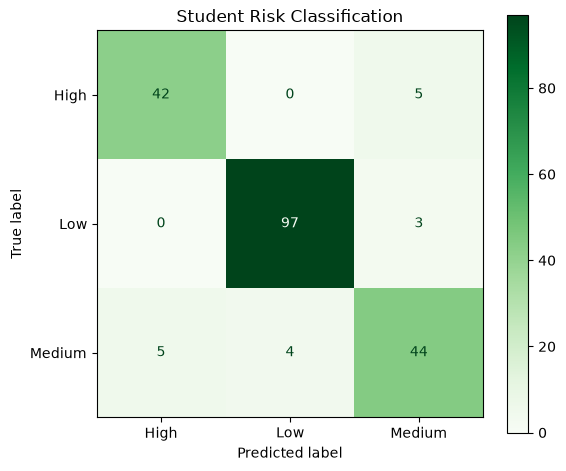

In [38]:
# ============================================================
# EVALUATE HELD-OUT DATA
# ============================================================
predictions = model.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, predictions):.3f}')
print(classification_report(y_test, predictions, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap='Greens')
plt.title('Student Risk Classification')
plt.tight_layout()
plt.show()

## Refit on all labeled rows and save
After evaluation, train the final artifact on all historical labeled rows. The Flask risk endpoint can then use the same fitted preprocessing and classifier pipeline.

In [39]:
# ============================================================
# TRAIN FINAL MODEL AND SAVE ARTIFACT
# ============================================================
final_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_split=4, class_weight='balanced', random_state=42)),
])
final_model.fit(X, y)
output_dir = MODEL_FILE / 'ModelOutput'
output_dir.mkdir(parents=True, exist_ok=True)
artifact_path = output_dir / 'risk_model.joblib'
joblib.dump(final_model, artifact_path)
print(f'Model pipeline saved to: {artifact_path}')

Saved trained model: D:\Research\new\EduPulse\EduPulse\python\RiskAssessment\ModelOutput\risk_model.joblib
File size: 16,522,755 bytes


In [40]:
# ============================================================
# SCORE MANUALLY ENTERED STUDENT/MODULE ROWS
# ============================================================
if not MANUAL_FILE.exists():
    raise FileNotFoundError(f'Missing manual input CSV: {MANUAL_FILE}')
manual = pd.read_csv(MANUAL_FILE)
required = ['student_id', 'student_name', 'module_id', 'module_name'] + FEATURES
missing = [column for column in required if column not in manual.columns]
if missing:
    raise ValueError(f'Manual input CSV is missing columns: {missing}')
if manual.empty:
    print('No manual student/module rows to assess.')
else:
    manual['risk_level'] = model.predict(manual[FEATURES])
    manual['confidence'] = model.predict_proba(manual[FEATURES]).max(axis=1)
    display_columns = [
        'student_id', 'student_name', 'module_id', 'module_name',
        'risk_level', 'confidence', 'quiz_accuracy', 'engagement_score',
        'previous_gpa', 'contextual_difficulty_level',
    ]
    print('Predicted risk for every manually entered module:')
    display(manual[display_columns])
    at_risk = manual[manual['risk_level'].isin(['High', 'Medium'])]
    print(f'{len(at_risk)} High/Medium risk module(s) from {len(manual)} manual row(s).')
    if at_risk.empty:
        print('The model classified all rows as Low risk. Review the training labels and feature quality before relying on this result.')

Predicted risk for every manually entered module:


,student_id,student_name,module_id,module_name,risk_level,confidence,quiz_accuracy,engagement_score,previous_gpa,contextual_difficulty_level
0,STU001,Amanda Perera,CS101,Introduction to Programming,High,0.990679,32,32,2.0,High
1,STU001,Amanda Perera,CS102,Data Structures,Medium,0.664834,78,63,2.1,Medium
2,STU002,Kasun Silva,CS101,Introduction to Programming,High,0.995778,49,38,2.4,High
3,STU004,Nimal Perera,CS103,Database Fundamentals,High,0.726250,50,60,2.0,High


4 High/Medium risk module(s) from 4 manual row(s).
